# Neutrino mass models with NeutrinoMassModels.jl

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/JuliaNeutrino/NeutrinoMassModels.jl/blob/main/notebooks/01_neutrino_mass_models.ipynb)

Oscillation experiments measure mixing angles and mass splittings. A model of neutrino mass has to *produce* them from a Lagrangian. NeutrinoMassModels.jl connects the two ends:

1. **Particle models** are written as Mathematica-style model files (gauge groups, fields, Lagrangian). The package reads them, checks the gauge and global invariance of each term and computes the tree-level spectrum.
2. **Mass mechanisms** (the scotogenic one-loop model and the type-I seesaw) turn model parameters into the light neutrino mass matrix, then into oscillation parameters that [GLoBES.jl](https://github.com/JuliaNeutrino/GLoBES.jl) understands.
3. The **Casas–Ibarra parametrisation** goes backwards, from oscillation data to the Yukawa couplings. Those couplings give lepton-flavour-violating decays such as μ → eγ.

The running example is the scotogenic model of E. Ma (hep-ph/0601225). It adds three singlet fermions $N_k$ and an inert scalar doublet $\eta$, all odd under a $\mathbb{Z}_2$. The neutrinos get their masses at one loop, and the lightest $\mathbb{Z}_2$-odd particle is a dark-matter candidate.

In [ ]:
# Install GLoBES.jl and NeutrinoMassModels.jl from GitHub, plus Plots (the first run takes a few minutes).
# On your own computer, skip this cell if they are already installed.
using Pkg
Pkg.add(url = "https://github.com/JuliaNeutrino/GLoBES.jl")
Pkg.add(url = "https://github.com/JuliaNeutrino/NeutrinoMassModels.jl")
Pkg.add("Plots")

In [1]:
using NeutrinoMassModels, GLoBES, LinearAlgebra, Plots
paper_theme!()   # Plots defaults for publication figures

## A model directory

A model is a directory with the model file (`Scotogenic.m`) and, optionally, `particles.m`, `parameters.m` and `SPheno.m` next to it. These files follow the conventions of SARAH. Each field is `{name, generations, components, U(1)_Y, SU(2), SU(3), Z2}`, and the Lagrangian is written with `.` for contracted products. `parameters.m` gives LaTeX names and the positions of parameters in LesHouches files.

In [2]:
dir = mkpath(joinpath(mktempdir(), "Scotogenic"))
write(joinpath(dir, "Scotogenic.m"), """
Model`Name = "Scotogenic";
Global[[1]] = {Z[2], Z2};
Gauge[[1]] = {B,  U[1], hypercharge, g1, False, 1};
Gauge[[2]] = {WB, SU[2], left,       g2, True,  1};
Gauge[[3]] = {G,  SU[3], color,      g3, False, 1};
FermionFields[[1]] = {q, 3, {uL, dL}, 1/6, 2, 3, 1};
FermionFields[[2]] = {l, 3, {vL, eL}, -1/2, 2, 1, 1};
FermionFields[[3]] = {d, 3, conj[dR], 1/3, 1, -3, 1};
FermionFields[[4]] = {u, 3, conj[uR], -2/3, 1, -3, 1};
FermionFields[[5]] = {e, 3, conj[eR], 1, 1, 1, 1};
FermionFields[[6]] = {n, 3, conj[nR], 0, 1, 1, -1};
ScalarFields[[1]] = {H, 1, {Hp, H0}, 1/2, 2, 1, 1};
ScalarFields[[2]] = {Et, 1, {etp, et0}, 1/2, 2, 1, -1};
NameOfStates = {GaugeES, EWSB};
DEFINITION[GaugeES][LagrangianInput] = {
    {LagFer, {AddHC->True}}, {LagNV, {AddHC->True}}, {LagH, {AddHC->False}},
    {LagEt, {AddHC->False}}, {LagHEt, {AddHC->False}}, {LagHEtHC, {AddHC->True}}
};
LagFer = Yd conj[H].d.q + Ye conj[H].e.l + Yu H.u.q + Yn Et.n.l;
LagNV = Mn/2 n.n;
LagH = -(-mH2 conj[H].H + 1/2 lambda1 conj[H].H.conj[H].H);
LagEt = -(+mEt2 conj[Et].Et + 1/2 lambda2 conj[Et].Et.conj[Et].Et);
LagHEt = -(+lambda3 conj[H].H.conj[Et].Et + lambda4 conj[H].Et.conj[Et].H);
LagHEtHC = -(+1/2 lambda5 conj[H].Et.conj[H].Et);
DEFINITION[EWSB][VEVs] = {
    {H0,  {v, 1/Sqrt[2]}, {Ah, I/Sqrt[2]}, {hh, 1/Sqrt[2]}},
    {et0, {0, 0}, {etI, I/Sqrt[2]}, {etR, 1/Sqrt[2]}}
};
""")
write(joinpath(dir, "parameters.m"), """
ParameterDefinitions = {
    {Yn,      {LaTeX -> "Y_N", LesHouches -> YN}},
    {Mn,      {LaTeX -> "M_N", LesHouches -> MN}}
};
""")
scoto = load_particle_model(dir)

BSMModel "Scotogenic"
  gauge group: U(1)_hypercharge × SU(2)_left × SU(3)_color
  global:      Z2
  q        fermion ×3  (1/6, 2, 3, 1)
  l        fermion ×3  (-1/2, 2, 1, 1)
  d        fermion ×3  (1/3, 1, -3, 1)
  u        fermion ×3  (-2/3, 1, -3, 1)
  e        fermion ×3  (1, 1, 1, 1)
  n        fermion ×3  (0, 1, 1, -1)
  H        scalar  ×1  (1/2, 2, 1, 1)
  Et       scalar  ×1  (1/2, 2, 1, -1)
  Lagrangian:  LagFer, LagNV, LagH, LagEt, LagHEt, LagHEtHC

## Checking the model

`check_model` expands every Lagrangian term (and its Hermitian conjugate) into monomials of field components. It then checks that each monomial is neutral under U(1)_Y, a singlet under SU(2) and SU(3), even under Z₂, and of mass dimension ≤ 4.

In [3]:
check_model(scoto)

Model check of "Scotogenic": 12 terms, all invariant
  ! parameters not in parameters.m (no LaTeX name or LesHouches entry): Yd, Ye, Yu, lambda1, lambda2, lambda3, lambda4, lambda5, mEt2, mH2


A typo that writes `H` instead of `Et` in the neutrino Yukawa breaks the Z₂ and lets the dark-matter candidate decay. A wrong field in the charged-lepton Yukawa breaks hypercharge. The check catches both:

In [4]:
broken = load_particle_model(dir)
add_lagrangian!(broken, :LagTypo, "Yb H.n.l + Yc H.e.l"; hc = true)
check_model(broken)

Model check of "Scotogenic": 14 terms, 2 problems
  ✗ LagTypo, term 1 (Yb H n l): Z2 parity is odd
  ✗ LagTypo, term 2 (Yc H e l): hypercharge charge 1 ≠ 0
  ! parameters not in parameters.m (no LaTeX name or LesHouches entry): Yb, Yc, Yd, Ye, Yu, lambda1, lambda2, lambda3, lambda4, lambda5, mEt2, mH2


The same model can be built in Julia without files, with `add_gauge!`, `add_fermion!`, `add_scalar!`, … Here is the lepton and scalar sector:

In [5]:
j = BSMModel("Scotogenic, by hand")
add_gauge!(j, :B, :U1, :hypercharge, :g1)
add_gauge!(j, :WB, (:SU, 2), :left, :g2; expand = true)
add_gauge!(j, :G, (:SU, 3), :color, :g3)
add_global!(j, :Z2; Z = 2)
add_fermion!(j, :l, 3, [:vL, :eL], -1 // 2, 2, 1, 1)
add_fermion!(j, :n, 3, :nR, 0, 1, 1, -1; conjugated = true)
add_scalar!(j, :H, 1, [:Hp, :H0], 1 // 2, 2, 1, 1)
add_scalar!(j, :Et, 1, [:etp, :et0], 1 // 2, 2, 1, -1)
add_lagrangian!(j, :LagNu, "Yn Et.n.l + Mn/2 n.n"; hc = true)
check_model(j)

Model check of "Scotogenic, by hand": 2 terms, all invariant


## The tree-level spectrum

`spectrum` builds the scalar potential from the Lagrangian, solves the tadpole equation for the parameters named in `tadpoles` (here the Higgs mass parameter), and diagonalises the mass matrices numerically. Masses are in GeV.

In [6]:
values = Dict{Symbol, Any}(:v => 246.22, :lambda1 => 0.26, :lambda2 => 0.1, :lambda3 => 0.2, :lambda4 => -0.1, :lambda5 => 1e-9,
                           :mEt2 => 1e6, :Mn => Diagonal([1e3, 2e3, 3e3]))
s = spectrum(scoto, values; tadpoles = [:mH2])

Tree-level spectrum of "Scotogenic" (GeV)
  mH2        = 7881.16  (tadpole)
  m(Hp) = 0
  m(Ah) = 0
  m(hh) = 125.548
  m(etI) = 1001.51
  m(etR) = 1001.51
  m(etp) = 1003.03
  m(n) = 1000, 2000, 3000


The Higgs comes out at √λ₁ v ≈ 125.5 GeV. The neutral inert scalars η_R and η_I are split by λ₅v²/(2m_η), which is tiny for λ₅ = 10⁻⁹. That splitting is exactly what the neutrino masses come from: with λ₅ = 0 lepton number is conserved and the loop vanishes.

## From the Lagrangian to the light neutrinos

`ScotogenicLoop()` computes the one-loop mass matrix

$$(M_\nu)_{\alpha\beta} = \sum_k \frac{Y_{k\alpha} Y_{k\beta}\, M_k}{32\pi^2}\left[\frac{m_R^2}{m_R^2 - M_k^2}\ln\frac{m_R^2}{M_k^2} - (R \to I)\right].$$

Instead of guessing Yukawas, `casas_ibarra` solves for the $Y$ that gives NuFIT 6.1 exactly, for a chosen lightest mass, Majorana phases and complex orthogonal matrix $R$:

In [7]:
mech = ScotogenicLoop()   # parameter names as in the model file
values[:Yn] = casas_ibarra(mech, values, nufit_params("6.1"); lightest = 1e-3)

3×3 Matrix{ComplexF64}:
   0.083988+0.0im       -0.0335544-0.00396503im  0.0471898-0.00421052im
   0.155997+0.0im         0.186306-0.00736453im  -0.146484-0.00782049im
 -0.0920543-0.046904im    0.466958+0.0im          0.495869+0.0im

In [8]:
ν = neutrino_spectrum(mech, values)   # masses, angles, phases and the observables of β and 0νββ decay

Light neutrinos (normal ordering)
  m₁, m₂, m₃ = 0.001, 0.008739, 0.05022 eV   Σm = 0.05996 eV
  sin²θ12 = 0.3088   sin²θ13 = 0.02249   sin²θ23 = 0.4700   δ = 207.0°
  Δm²21 = 7.537e-05 eV²   Δm²31 = 0.002521 eV²
  α21 = 0.0°, α31 = 0.0°   mββ = 0.004081 eV   mβ = 0.008969 eV

The angles, δ and both splittings are NuFIT's. The same Yukawas also mediate μ → eγ through a loop of the charged scalar η⁺ and the $N_k$. With these parameters the branching ratio sits right at the MEG II limit of 1.5 × 10⁻¹³:

In [9]:
(μ_eγ = br_lfv(mech, values, :μ, :e), τ_μγ = br_lfv(mech, values, :τ, :μ), τ_eγ = br_lfv(mech, values, :τ, :e))

(μ_eγ = 1.588334634682515e-13, τ_μγ = 2.4720554952943756e-12, τ_eγ = 4.34381197116324e-13)

## μ → eγ against λ₅

For fixed neutrino masses $Y^2 \propto 1/\lambda_5$, so BR(μ → eγ) ∝ $Y^4 \propto 1/\lambda_5^2$. Small λ₅, which is technically natural because λ₅ → 0 restores lepton number, therefore means large Yukawas and large lepton flavour violation. Here is the scan for three inert mass scales, with $M_k = (1, 2, 3)\, m_\eta$:

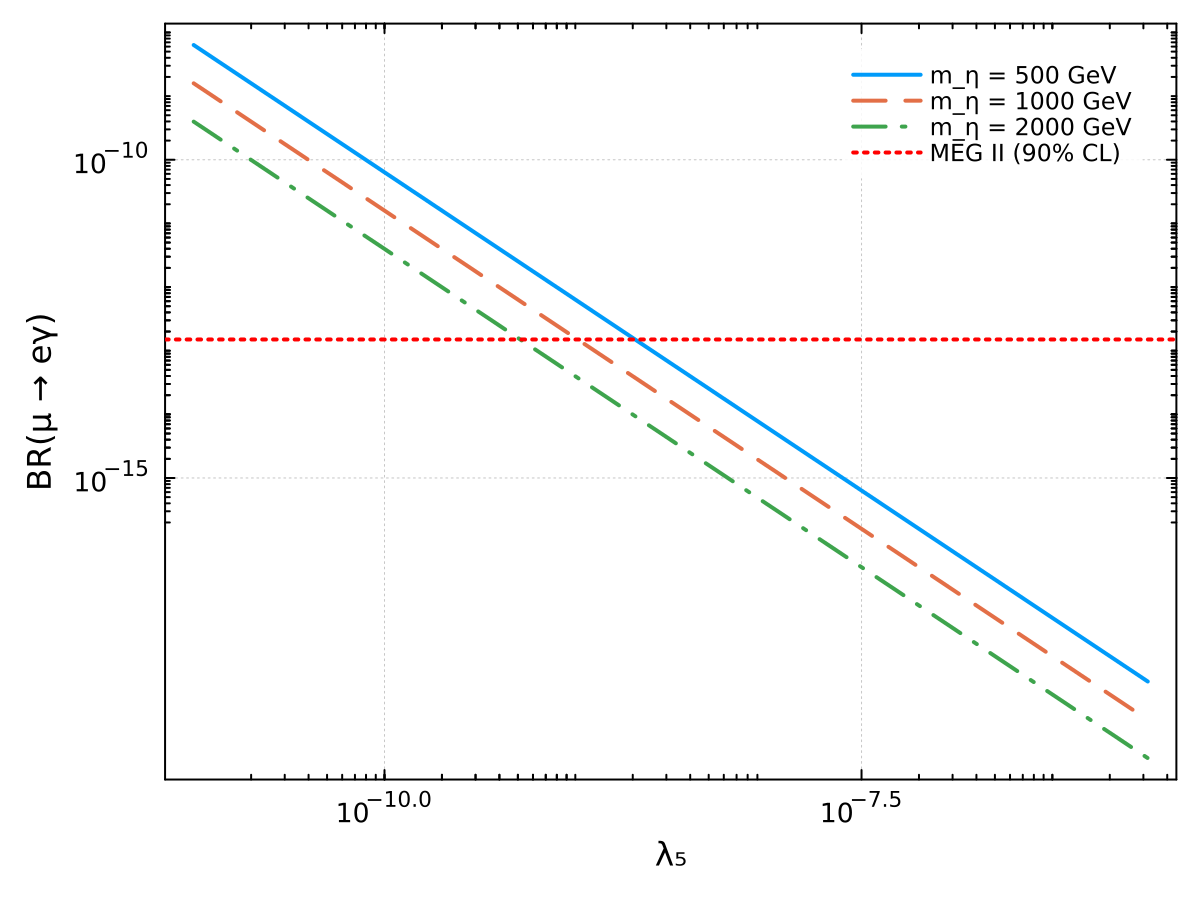

In [10]:
λ5s = 10 .^ range(-11, -6, 41)
plt = plot(; xscale = :log10, yscale = :log10, xlabel = "λ₅", ylabel = "BR(μ → eγ)", legend = :topright)
for (mη, style) in ((500, :solid), (1000, :dash), (2000, :dashdot))
    br = map(λ5s) do λ5
        v = merge(values, Dict(:lambda5 => λ5, :mEt2 => mη^2, :Mn => Diagonal([1, 2, 3] .* mη)))
        v[:Yn] = casas_ibarra(mech, v, nufit_params("6.1"); lightest = 1e-3)
        br_lfv(mech, v)
    end
    plot!(plt, λ5s, br; label = "m_η = $mη GeV", linestyle = style)
end
hline!(plt, [1.5e-13]; color = :red, linestyle = :dot, label = "MEG II (90% CL)")

Everything above the red line is excluded. At λ₅ ≈ 10⁻¹¹ the largest Yukawa is also above 3, close to the perturbative limit:

In [11]:
[(λ5 = λ5, largest_Y = maximum(abs, casas_ibarra(mech, merge(values, Dict(:lambda5 => λ5)), nufit_params("6.1"); lightest = 1e-3))) for λ5 in (1e-11, 1e-9, 1e-7)]

3-element Vector{@NamedTuple{λ5::Float64, largest_Y::Float64}}:
 (λ5 = 1.0e-11, largest_Y = 4.958495609814246)
 (λ5 = 1.0e-9, largest_Y = 0.49586908002177515)
 (λ5 = 1.0e-7, largest_Y = 0.04958692371355978)

## The type-I seesaw

`TypeISeesaw()` gives $M_\nu = -\frac{v^2}{2} Y^T M^{-1} Y$. Casas–Ibarra again gives the Yukawas, which grow like $\sqrt{M}$. For $M \sim 10^{14}$ GeV they are of order one, which is the usual argument that the seesaw scale is close to the GUT scale:

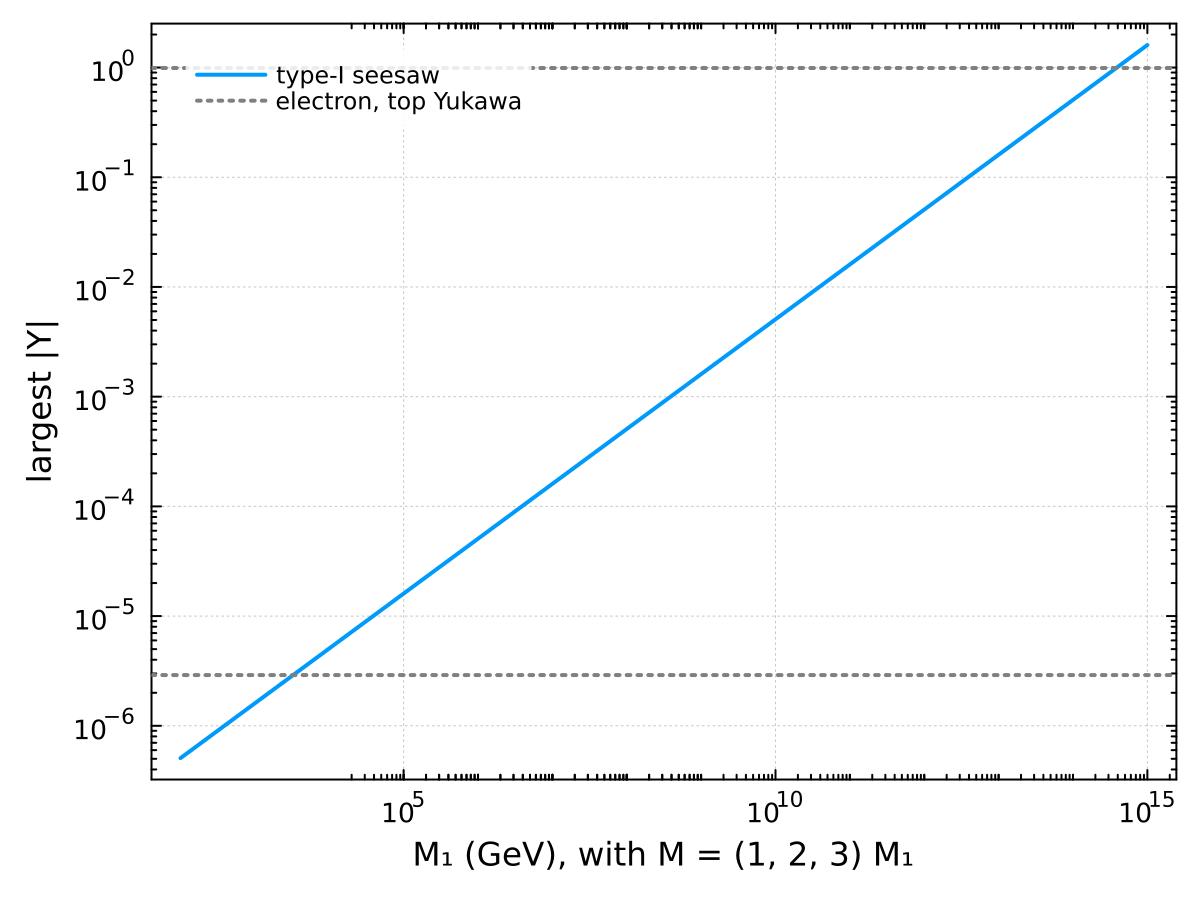

In [12]:
seesaw = TypeISeesaw()
Ms = 10 .^ range(2, 15, 53)
largest = [maximum(abs, casas_ibarra(seesaw, Dict{Symbol, Any}(:v => 246.22, :Mn => Diagonal([M, 2M, 3M])), nufit_params("6.1"); lightest = 1e-3)) for M in Ms]
plot(Ms, largest; xscale = :log10, yscale = :log10, xlabel = "M₁ (GeV), with M = (1, 2, 3) M₁", ylabel = "largest |Y|", label = "type-I seesaw", legend = :topleft)
hline!([2.9e-6, 0.99]; color = :gray, linestyle = :dot, label = "electron, top Yukawa")

## Neutrinoless double-β decay

`neutrino_spectrum` works on any Majorana mass matrix, not only those of a mechanism. Building $M_\nu = U^* \mathrm{diag}(m)\, U^\dagger$ from NuFIT for every lightest mass and every pair of Majorana phases gives the allowed band of the effective mass $m_{\beta\beta} = |(M_\nu)_{ee}|$. This is the well-known "lobster" plot:

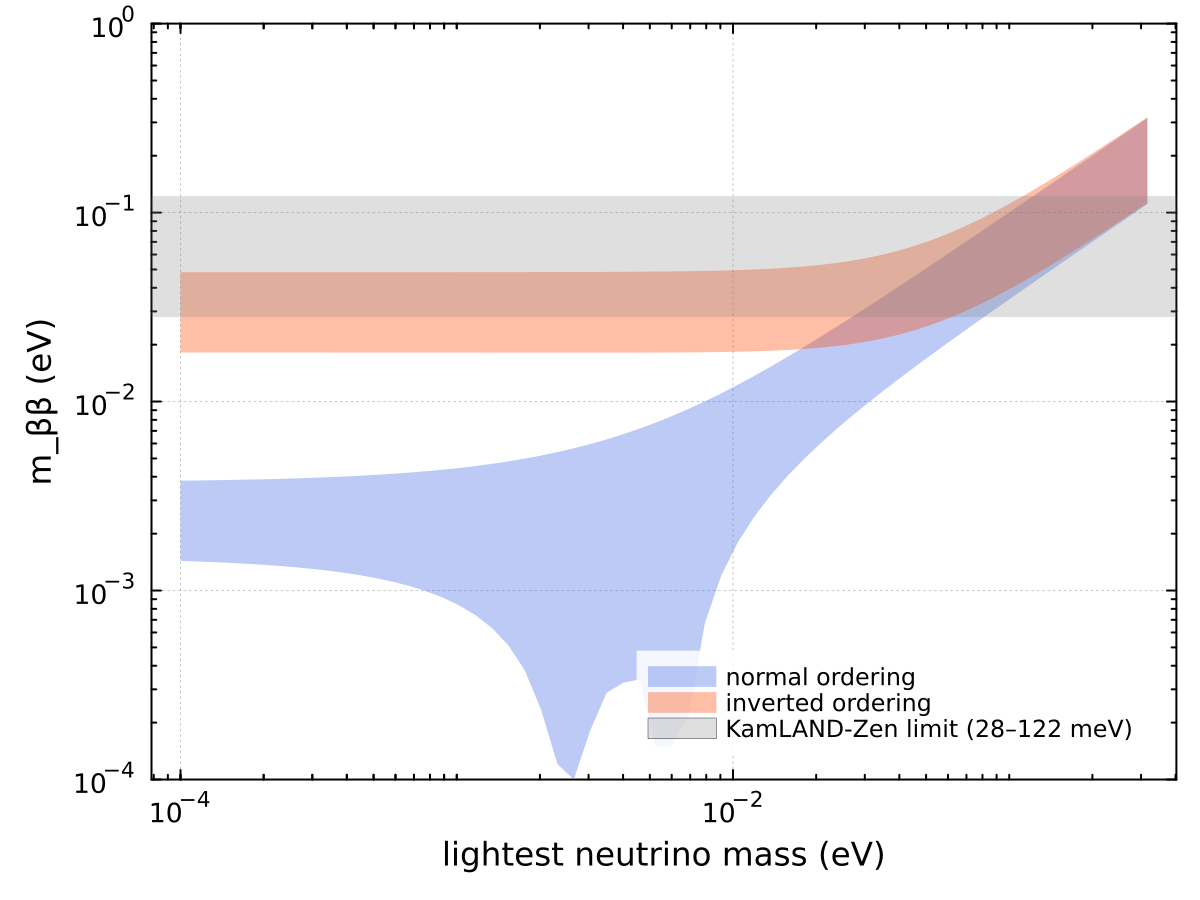

In [13]:
mℓ = 10 .^ range(-4, -0.5, 60)
phases = range(0, 2π, 25)
mββ(q, m, α) = neutrino_spectrum(conj(pmns_matrix(q; majorana_phases = α)) * Diagonal(light_masses(q; lightest = m)) * pmns_matrix(q; majorana_phases = α)').mββ
plt = plot(; xscale = :log10, yscale = :log10, xlabel = "lightest neutrino mass (eV)", ylabel = "m_ββ (eV)", legend = :bottomright, ylims = (1e-4, 1))
for (label, q, colour) in (("normal", nufit_params("6.1"), :royalblue), ("inverted", nufit_params("6.1"; ordering = :inverted), :orangered))
    band = [extrema(mββ(q, m, (a21, a31)) for a21 in phases, a31 in phases) for m in mℓ]
    lo = max.(first.(band), 1e-4)
    plot!(plt, mℓ, lo; fillrange = last.(band), fillalpha = 0.35, color = colour, linealpha = 0, label = "$label ordering")
end
hspan!(plt, [0.028, 0.122]; color = :gray, alpha = 0.25, label = "KamLAND-Zen limit (28–122 meV)")

The inverted band stays above about 18 meV, which next-generation experiments (LEGEND-1000, nEXO) aim to reach. The normal band dips towards zero near $m_\text{lightest} \approx$ 2–7 meV, where the three terms of $(M_\nu)_{ee}$ can cancel.

## LesHouches files and LaTeX

`write_leshouches` writes the matrices to the blocks that `parameters.m` names (`YN` and `MN` here), which is the input format for spectrum generators such as SPheno. Scalar inputs go to `MINPAR` through the `SPheno.m` of the model. `leshouches_values` reads them back:

In [14]:
file = joinpath(dir, "LesHouches.in")
write_leshouches(file, scoto, values)
print(read(file, String))

# LesHouches input for model Scotogenic, written by GLoBES.jl
Block MN   # Mn
  1   1    1.00000000E+03
  1   2    0.00000000E+00
  1   3    0.00000000E+00
  2   1    0.00000000E+00
  2   2    2.00000000E+03
  2   3    0.00000000E+00
  3   1    0.00000000E+00
  3   2    0.00000000E+00
  3   3    3.00000000E+03
Block YN   # Yn
  1   1    8.39879779E-02
  1   2   -3.35544475E-02
  1   3    4.71898347E-02
  2   1    1.55996623E-01
  2   2    1.86306161E-01
  2   3   -1.46484294E-01
  3   1   -9.20543045E-02
  3   2    4.66958218E-01
  3   3    4.95869080E-01
Block IMYN   # Yn
  1   1    0.00000000E+00
  1   2   -3.96503424E-03
  1   3   -4.21052207E-03
  2   1    0.00000000E+00
  2   2   -7.36452964E-03
  2   3   -7.82049100E-03
  3   1   -4.69040109E-02
  3   2    0.00000000E+00
  3   3    0.00000000E+00


In [15]:
back = leshouches_values(scoto, file)
back[:Yn] ≈ values[:Yn], back[:Mn] ≈ values[:Mn]

(true, true)

`latex` writes the results as tables for a GLoBES.jl `TexReport`:

In [16]:
print(latex(ν))

\begin{table}[htbp]
\centering
\begin{tabular}{ll}
\toprule
Light neutrinos &  \\
\midrule
$m_1, m_2, m_3$ & $10 \times 10^{-4}, 0.008739, 0.05022$ eV \\
ordering & normal \\
$\sin^2\theta_{12}, \sin^2\theta_{13}, \sin^2\theta_{23}$ & $0.3088, 0.02249, 0.47$ \\
$\delta_{\mathrm{CP}}, \alpha_{21}, \alpha_{31}$ & $207^\circ, 0^\circ, 0^\circ$ \\
$\Delta m^2_{21}, \Delta m^2_{31}$ & $7.537 \times 10^{-5}, 0.002521$ eV$^2$ \\
$\sum m_i, m_\beta, m_{\beta\beta}$ & $0.05996, 0.008969, 0.004081$ eV \\
\bottomrule
\end{tabular}
\end{table}
